# Kaplan-Meier and Nelson-Aalen estimators with `scikit-survival`

The same estimators once more, now with the library `scikit-survival` (`sksurv`), which follows the conventions of `scikit-learn`. Its functions return arrays: the times, the estimate at each time and, if asked, the confidence interval.

The data are the times, in weeks, to discontinuation of the use of an intrauterine device (IUD) for 18 women.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sksurv.nonparametric import kaplan_meier_estimator, nelson_aalen_estimator

In [2]:
# Colors shared by all the plots
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
opt_color   = '#E69F00'

## The data

In [3]:
DatOriginal = pd.read_csv("data/iud_discontinuation.dat", sep=r"\s+")

## Kaplan-Meier estimator

The confidence interval of type `log-log` is the one obtained in the first notebook from the interval of $\log H(t)$.

In [4]:
time, survival_prob, conf_int = kaplan_meier_estimator(
    DatOriginal["status"].astype(bool), DatOriginal["time"], conf_type="log-log"
)

In [5]:
pd.DataFrame({'time': time, 'survival_prob': survival_prob, 'lower': conf_int[0], 'upper': conf_int[1]}).round(4)

,time,survival_prob,lower,upper
0,10,0.9444,0.6664,0.9920
1,13,0.9444,0.6664,0.9920
2,18,0.9444,0.6664,0.9920
3,19,0.8815,0.6019,0.9691
4,23,0.8815,0.6019,0.9691
5,30,0.8137,0.5241,0.9363
6,36,0.7459,0.4536,0.8970
7,38,0.7459,0.4536,0.8970
8,54,0.7459,0.4536,0.8970
9,56,0.7459,0.4536,0.8970


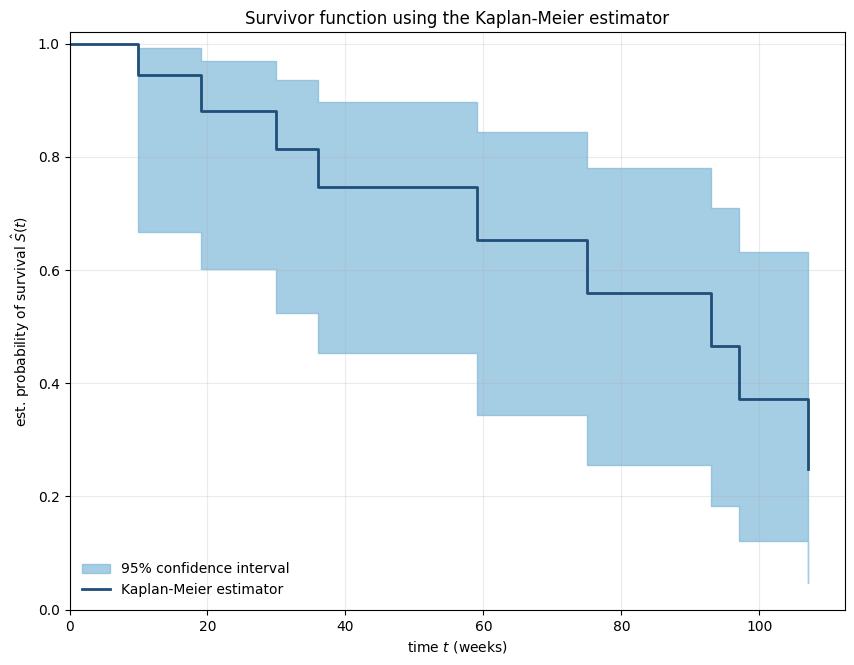

In [6]:
# The arrays start at the first observed time; the curve is 1 before it
time_plot = np.append(0, time)

plt.figure(figsize=(10, 7.5))
plt.fill_between(time_plot, np.append(1, conf_int[0]), np.append(1, conf_int[1]), step="post", color=ci_color, alpha=0.7,
                 label='95% confidence interval')
plt.step(time_plot, np.append(1, survival_prob), where="post", color=line_color, lw=2, label='Kaplan-Meier estimator')
plt.ylim(0, 1.02)
plt.xlim(0, None)
plt.ylabel(r"est. probability of survival $\hat{S}(t)$")
plt.xlabel("time $t$ (weeks)")
plt.title('Survivor function using the Kaplan-Meier estimator')
plt.legend(loc='lower left', frameon=False)
plt.grid(True, alpha=0.25)

## Nelson-Aalen estimator

In [7]:
_, cummulative_hazard = nelson_aalen_estimator(
    DatOriginal["status"].astype(bool), DatOriginal["time"]
)

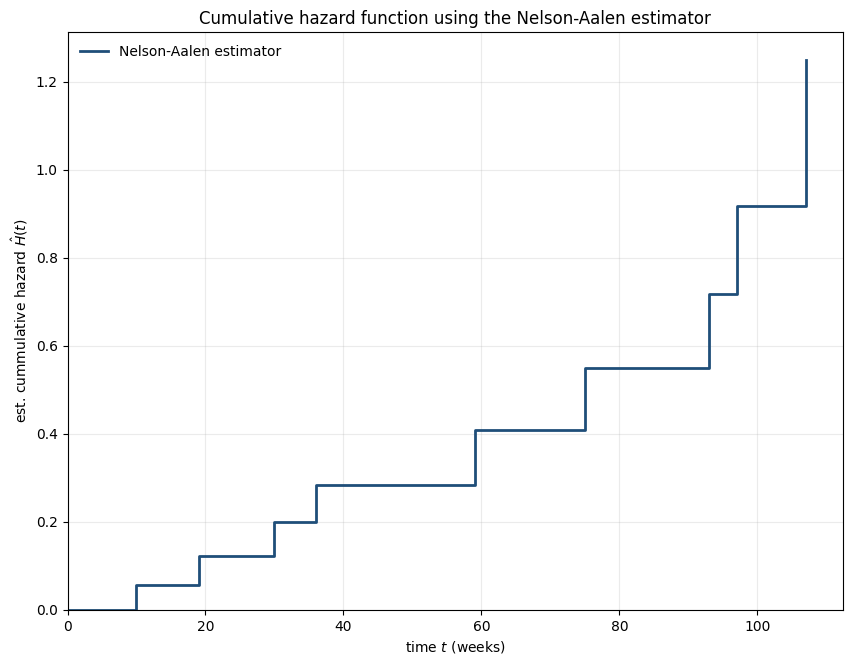

In [8]:
plt.figure(figsize=(10, 7.5))
plt.step(time_plot, np.append(0, cummulative_hazard), where="post", color=line_color, lw=2, label='Nelson-Aalen estimator')
plt.ylim(0, None)
plt.xlim(0, None)
plt.ylabel(r"est. cummulative hazard $\hat{H}(t)$")
plt.xlabel("time $t$ (weeks)")
plt.title('Cumulative hazard function using the Nelson-Aalen estimator')
plt.legend(loc='upper left', frameon=False)
plt.grid(True, alpha=0.25)

## Median

The median is the first time at which the estimated survivor function is 0.5 or less.

In [9]:
time[survival_prob<=0.5].min()

np.int64(93)

The times $\hat u$ and $\hat l$ needed for the standard error of the median (see the first notebook) are also read directly from the arrays.

In [10]:
EPSILON = 0.05

In [11]:
u = time[survival_prob>=1-0.5+EPSILON].max()
l = time[survival_prob<=1-0.5-EPSILON].min()

In [12]:
u, l

(np.int64(75), np.int64(97))

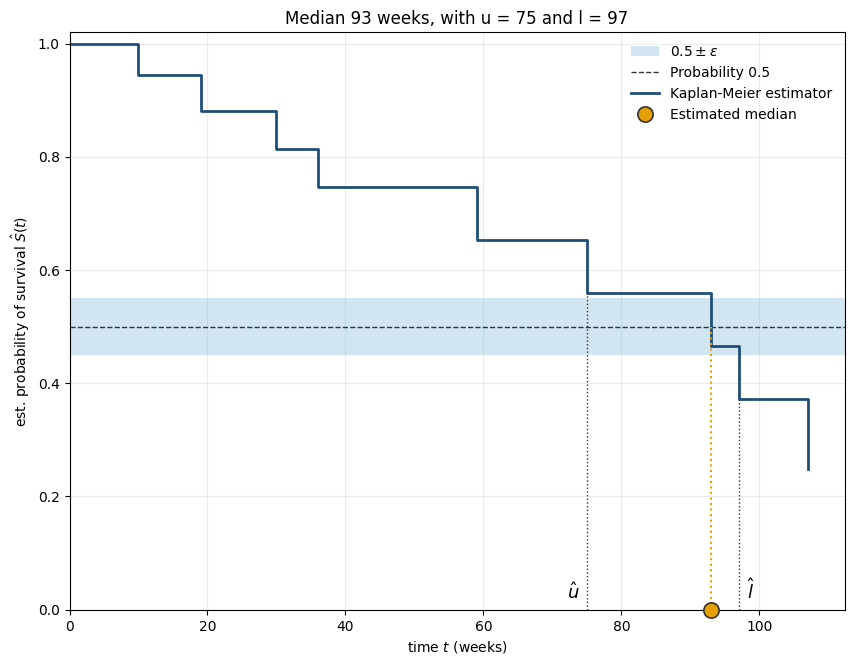

In [13]:
median = time[survival_prob<=0.5].min()

plt.figure(figsize=(10, 7.5))
plt.axhspan(0.5-EPSILON, 0.5+EPSILON, color=ci_color, alpha=0.35, lw=0, label=r'$0.5\pm\epsilon$')
plt.axhline(0.5, color='#333333', lw=1, ls='--', label='Probability 0.5')
plt.step(time_plot, np.append(1, survival_prob), where="post", color=line_color, lw=2, label='Kaplan-Meier estimator')
plt.vlines([u, l], 0, [survival_prob[time == u][0], survival_prob[time == l][0]], color='#333333', lw=1, ls=':')
plt.vlines(median, 0, 0.5, color=opt_color, lw=1.5, ls=':')
plt.plot(median, 0, 'o', color=opt_color, markersize=11, markeredgecolor='#333333', markeredgewidth=1.2, clip_on=False,
         zorder=6, label='Estimated median')
plt.annotate(r'$\hat u$', (u, 0), xytext=(-14, 8), textcoords='offset points', fontsize=13)
plt.annotate(r'$\hat l$', (l, 0), xytext=(6, 8), textcoords='offset points', fontsize=13)
plt.ylim(0, 1.02)
plt.xlim(0, None)
plt.ylabel(r"est. probability of survival $\hat{S}(t)$")
plt.xlabel("time $t$ (weeks)")
plt.title(f'Median {median} weeks, with u = {u} and l = {l}')
plt.legend(loc='upper right', frameon=False)
plt.grid(True, alpha=0.25)